In [18]:
import os
os.environ["OPENROUTER_API_KEY"] = "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"

# 02 - Layer 2 LLM Intelligence Layer

Two goals:

1. **Task 2A: Trend and Anomaly Detection** - inspect Layer 2 cluster alerts, PSI distribution shifts, and transaction anomalies.
2. **Task 2B: LLM-Generated Deal Summary** - build a structured credit-review prompt for one deal and call an OpenRouter model when an API key is available.

OpenRouter exposes an OpenAI-compatible chat completions endpoint at `https://openrouter.ai/api/v1/chat/completions`, so the notebook uses the same messages pattern as OpenAI Chat Completions while routing through OpenRouter.

## 1. Setup

In [19]:
from pathlib import Path
import json
import os
import subprocess
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

pd.set_option('display.max_columns', 140)
pd.set_option('display.max_rows', 120)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

In [20]:
# Resolve project root whether running from repo root or notebooks/.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'scripts').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT / 'src'))

REPORTS_DIR = PROJECT_ROOT / 'reports'
DATE_COLS = ['invoice_date', 'expected_payment_date', 'actual_resolution_date']

from rawasi_credit.llm_summary import (
    build_deal_context,
    build_deal_summary_messages,
    call_openrouter_deal_summary,
)

print('Project root:', PROJECT_ROOT)
print('Python used by notebook:', sys.executable)

Project root: /Users/adi/Documents/ai_credit_intelligence
Python used by notebook: /usr/local/bin/python3


In [21]:
def run_project_script(script_name):
    script_path = PROJECT_ROOT / 'scripts' / script_name
    result = subprocess.run(
        [sys.executable, str(script_path)],
        cwd=PROJECT_ROOT,
        check=False,
        text=True,
        capture_output=True,
    )
    if result.stdout:
        print(result.stdout)
    if result.stderr:
        print(result.stderr)
    result.check_returncode()
    return result


def load_report(name, parse_dates=None):
    path = REPORTS_DIR / name
    if not path.exists():
        raise FileNotFoundError(f'Missing report: {path}')
    return pd.read_csv(path, parse_dates=parse_dates)


def pct(series):
    return series.astype(float).map(lambda x: f'{x:.1%}' if pd.notna(x) else '')

## 2. Run Layer 2 Pipeline

This reruns `scripts/run_layer2_intelligence.py` so the notebook always reflects the latest Stage B/Stage C reports.

In [22]:
run_project_script('run_layer2_intelligence.py')

Layer 2 intelligence complete.
Monitoring rows: 3,732
Trend clusters: 605; alerts: 15
Distribution shifts: 5 significant
Transaction anomalies: 214 alerts
Wrote: /Users/adi/Documents/ai_credit_intelligence/reports/layer2_intelligence_report.md



CompletedProcess(args=['/usr/local/bin/python3', '/Users/adi/Documents/ai_credit_intelligence/scripts/run_layer2_intelligence.py'], returncode=0, stdout='Layer 2 intelligence complete.\nMonitoring rows: 3,732\nTrend clusters: 605; alerts: 15\nDistribution shifts: 5 significant\nTransaction anomalies: 214 alerts\nWrote: /Users/adi/Documents/ai_credit_intelligence/reports/layer2_intelligence_report.md\n', stderr='')

In [23]:
monitoring = load_report('layer2_scored_monitoring_frame.csv', parse_dates=DATE_COLS)
clusters = load_report('layer2_trend_clusters.csv')
drift = load_report('layer2_distribution_shift.csv')
anomalies = load_report('layer2_transaction_anomalies.csv', parse_dates=['invoice_date'])

summary = pd.DataFrame({
    'metric': [
        'monitoring_rows',
        'stage_b_train_rows',
        'stage_b_validation_rows',
        'stage_b_open_holdout_rows',
        'trend_clusters',
        'trend_cluster_alerts',
        'distribution_shift_features',
        'significant_distribution_shifts',
        'transaction_anomaly_rows',
        'transaction_anomaly_alerts',
    ],
    'value': [
        len(monitoring),
        int(monitoring['stage_b_split'].eq('train').sum()),
        int(monitoring['stage_b_split'].eq('validation').sum()),
        int(monitoring['stage_b_split'].eq('open_holdout').sum()),
        len(clusters),
        int(clusters['alert_flag'].sum()),
        len(drift),
        int(drift['human_review_required'].sum()),
        len(anomalies),
        int(anomalies['layer2_anomaly_alert'].sum()),
    ]
})
summary

,metric,value
0,monitoring_rows,3732
1,stage_b_train_rows,3048
2,stage_b_validation_rows,431
3,stage_b_open_holdout_rows,253
4,trend_clusters,605
5,trend_cluster_alerts,15
6,distribution_shift_features,41
7,significant_distribution_shifts,5
8,transaction_anomaly_rows,684
9,transaction_anomaly_alerts,214


## 3. Task 2A - Trend Cluster Alerts

The trend detector compares validation-window default rates to training-window baselines for selected business clusters. A cluster alert means the recent default rate is high enough and has lifted materially versus the smoothed training baseline.

In [24]:
cluster_cols = [
    'cluster_definition', 'cluster_key', 'recent_rows', 'recent_defaults',
    'recent_default_rate', 'train_rows', 'train_defaults', 'train_default_rate',
    'default_rate_lift', 'recent_avg_predicted_probability',
    'model_underestimated_recent_risk', 'recent_default_minus_predicted', 'alert_flag'
]
alert_clusters = clusters.loc[clusters['alert_flag'], cluster_cols].copy()
alert_clusters.sort_values(['recent_default_rate', 'default_rate_lift'], ascending=False).head(20)

,cluster_definition,cluster_key,recent_rows,recent_defaults,recent_default_rate,train_rows,train_defaults,train_default_rate,default_rate_lift,recent_avg_predicted_probability,model_underestimated_recent_risk,recent_default_minus_predicted,alert_flag
0,buy_buyer_country + goods_category,Iraq / Metals,6,3,0.5000,17,0,0.0000,11.8125,0.5936,False,-0.0936,True
230,buy_buyer_country + exp_segment,Italy / LC,6,2,0.3333,68,4,0.0588,2.7083,0.2292,True,0.1041,True
266,buy_buyer_sector + goods_category,Agriculture - Agri Processing / Textiles,8,2,0.2500,16,0,0.0000,7.2222,0.2940,False,-0.0440,True
1,buy_buyer_country + goods_category,Spain / Food,5,1,0.2000,32,0,0.0000,8.4000,0.2255,False,-0.0255,True
267,buy_buyer_sector + goods_category,Printing and Packaging / Agricultural,5,1,0.2000,18,0,0.0000,5.6000,0.2572,False,-0.0572,True
2,buy_buyer_country + goods_category,Kenya / Chemicals,5,1,0.2000,25,1,0.0400,2.3333,0.7245,False,-0.5245,True
3,buy_buyer_country + goods_category,Germany / Textiles,6,1,0.1667,41,0,0.0000,9.5625,0.3199,False,-0.1533,True
430,exp_industry + goods_category,Textiles - Apparel Manufacturing / Textiles,6,1,0.1667,27,0,0.0000,6.9375,0.3982,False,-0.2316,True
431,exp_industry + goods_category,Fertilizer / Chemicals,6,1,0.1667,23,0,0.0000,6.1875,0.4647,False,-0.2981,True
268,buy_buyer_sector + goods_category,Textiles - Fabric Manufacturing / Metals,6,1,0.1667,21,0,0.0000,5.8125,0.3743,False,-0.2076,True


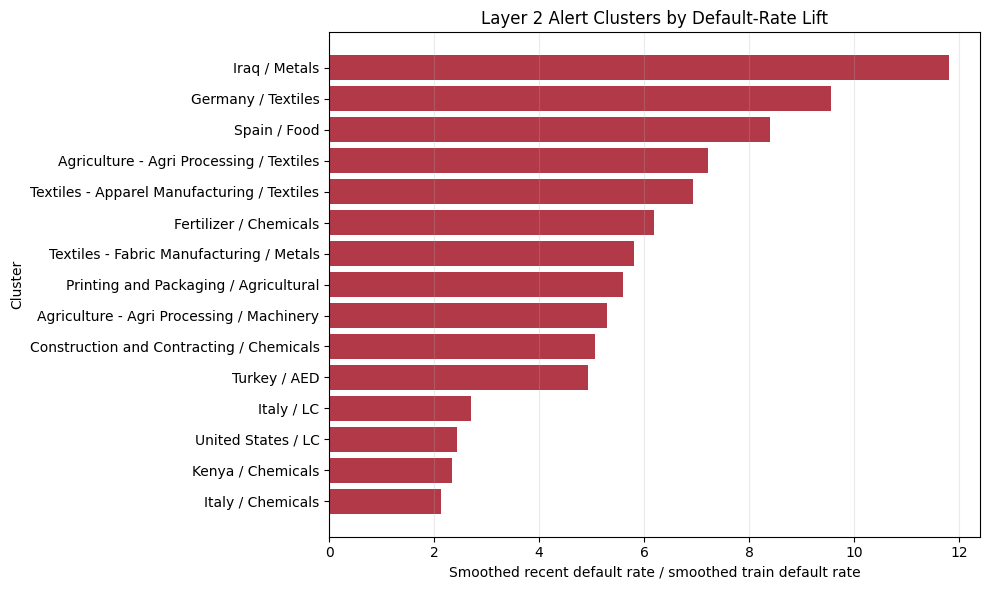

In [25]:
plot_df = alert_clusters.sort_values('default_rate_lift', ascending=True).tail(15)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_df['cluster_key'], plot_df['default_rate_lift'], color='#b23a48')
ax.set_title('Layer 2 Alert Clusters by Default-Rate Lift')
ax.set_xlabel('Smoothed recent default rate / smoothed train default rate')
ax.set_ylabel('Cluster')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()

## 4. Task 2A - Batch Distribution Shift

The batch alerting rule uses Population Stability Index (PSI) between training and validation distributions. A PSI above `0.25` is treated as a significant shift requiring human review.

In [26]:
drift.sort_values('psi', ascending=False).head(20)

,feature,psi,severity,human_review_required,baseline_rows,incoming_rows,baseline_missing_rate,incoming_missing_rate,baseline_mean,incoming_mean
0,log_cumulative_outstanding_usd,0.7954,significant_shift,True,3048,431,0.0000,0.0000,13.8109,15.5466
1,log_outstanding_to_revenue_est,0.4707,significant_shift,True,3048,431,0.0000,0.0000,1.7495,2.3599
2,outstanding_to_revenue_est,0.4707,significant_shift,True,3048,431,0.0000,0.0000,10.7898,16.9563
3,total_exposure_to_revenue_est,0.3613,significant_shift,True,3048,431,0.0000,0.0000,11.5229,17.6064
4,exposure_quality_pressure,0.3534,significant_shift,True,3048,431,0.0000,0.0000,24.2495,36.7366
5,advance_tenor_exposure,0.1589,moderate_shift,False,3048,431,0.0000,0.0000,63.0643,53.2096
6,stage_c_default_probability,0.1276,moderate_shift,False,3048,431,0.0000,0.0000,0.1950,0.2592
7,buyer_dso_to_terms,0.1120,moderate_shift,False,3048,431,0.0000,0.0000,1.2569,1.4521
8,buyer_terms_pressure,0.1089,moderate_shift,False,3048,431,0.0000,0.0000,0.2022,0.1683
9,exp_fx_loss_abs_pct,0.0921,stable,False,3048,431,0.0000,0.0000,5.6754,5.6384


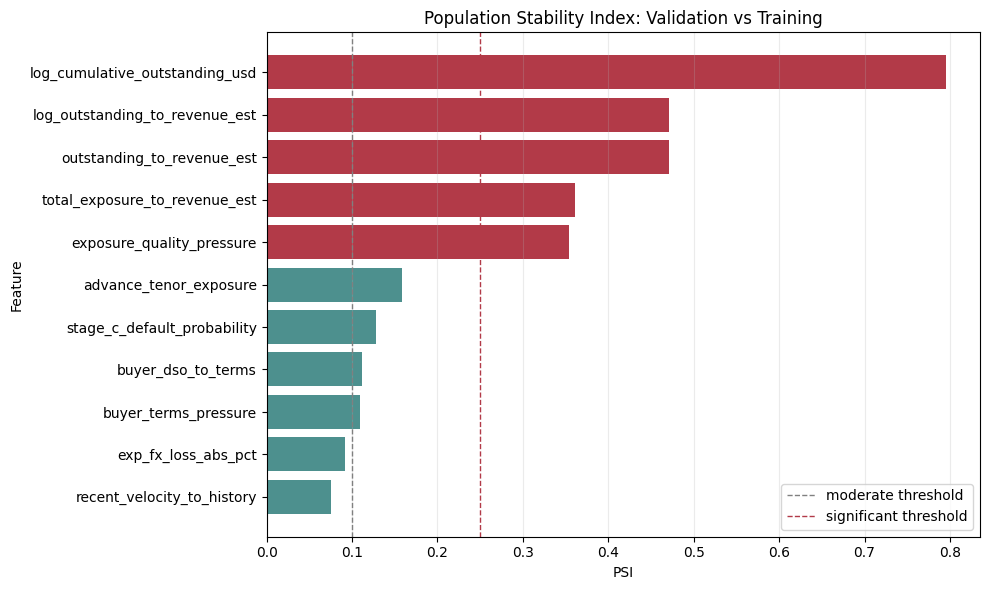

In [27]:
top_drift = drift.sort_values('psi', ascending=True).tail(15)
colors = np.where(top_drift['human_review_required'], '#b23a48', '#4d908e')

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_drift['feature'], top_drift['psi'], color=colors)
ax.axvline(0.10, color='gray', linestyle='--', linewidth=1, label='moderate threshold')
ax.axvline(0.25, color='#b23a48', linestyle='--', linewidth=1, label='significant threshold')
ax.set_title('Population Stability Index: Validation vs Training')
ax.set_xlabel('PSI')
ax.set_ylabel('Feature')
ax.legend()
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()

## 5. Task 2A - Transaction Anomaly Alerts

The transaction anomaly score ranks validation and open-holdout deals against the training distribution using Stage C probability, Stage B benchmark score, peer outlier score, and high-risk peer outlier count.

In [28]:
anomaly_cols = [
    'transaction_id', 'invoice_date', 'stage_b_split', 'status', 'defaulted',
    'buy_buyer_country', 'goods_category', 'invoice_currency',
    'stage_c_default_probability', 'stage_c_predicted_default',
    'stage_b_benchmark_score', 'stage_b_peer_high_risk_outlier_count',
    'probability_percentile_vs_train', 'benchmark_percentile_vs_train',
    'peer_score_percentile_vs_train', 'peer_count_percentile_vs_train',
    'layer2_anomaly_score', 'layer2_anomaly_alert', 'layer2_anomaly_reasons'
]
anomalies.loc[anomalies['layer2_anomaly_alert'], anomaly_cols].head(30)

,transaction_id,invoice_date,stage_b_split,status,defaulted,buy_buyer_country,goods_category,invoice_currency,stage_c_default_probability,stage_c_predicted_default,stage_b_benchmark_score,stage_b_peer_high_risk_outlier_count,probability_percentile_vs_train,benchmark_percentile_vs_train,peer_score_percentile_vs_train,peer_count_percentile_vs_train,layer2_anomaly_score,layer2_anomaly_alert,layer2_anomaly_reasons
0,TX-001804,2025-10-28,validation,defaulted,1.0000,Turkey,Machinery,AED,0.9766,1,75.0417,14,99.6391,98.5892,100.0000,98.4252,99.3274,True,above Stage C review threshold; probability ab...
1,TX-000417,2026-01-26,open_holdout,open,NaN,Algeria,Pharmaceuticals,EUR,0.9677,1,72.6262,14,99.3110,96.5551,100.0000,98.4252,98.6713,True,above Stage C review threshold; probability ab...
2,TX-004538,2025-10-29,open_holdout,open,NaN,Algeria,Textiles,EUR,0.9464,1,72.6020,14,98.9173,96.5551,100.0000,98.4252,98.4941,True,above Stage C review threshold; probability ab...
3,TX-003507,2026-03-07,open_holdout,open,NaN,Iraq,Agricultural,EUR,0.8661,1,78.6295,15,96.9488,99.7703,100.0000,99.1142,98.4810,True,above Stage C review threshold; probability ab...
4,TX-004831,2025-11-10,open_holdout,open,NaN,Iraq,Machinery,USD,0.8490,1,77.9845,17,96.5223,99.7047,100.0000,99.8031,98.3415,True,above Stage C review threshold; probability ab...
5,TX-001998,2025-11-29,open_holdout,open,NaN,Russia,Consumer Goods,EUR,0.8371,1,81.4953,15,96.4895,99.9672,100.0000,99.1142,98.3235,True,above Stage C review threshold; probability ab...
6,TX-004123,2026-02-16,open_holdout,open,NaN,Saudi Arabia,Metals,USD,0.9647,1,73.3455,10,99.2782,97.4409,100.0000,92.6509,98.3005,True,above Stage C review threshold; probability ab...
7,TX-000507,2025-12-21,open_holdout,open,NaN,India,Textiles,AED,0.9784,1,74.9697,8,99.7047,98.4908,100.0000,87.9593,98.2858,True,above Stage C review threshold; probability ab...
8,TX-003324,2025-12-16,open_holdout,open,NaN,Russia,Metals,EUR,0.8279,1,80.9409,15,96.3583,99.9672,100.0000,99.1142,98.2644,True,above Stage C review threshold; probability ab...
9,TX-002589,2026-01-06,open_holdout,open,NaN,United Kingdom,Textiles,GBP,0.9549,1,73.0544,10,99.1142,97.2769,100.0000,92.6509,98.1857,True,above Stage C review threshold; probability ab...


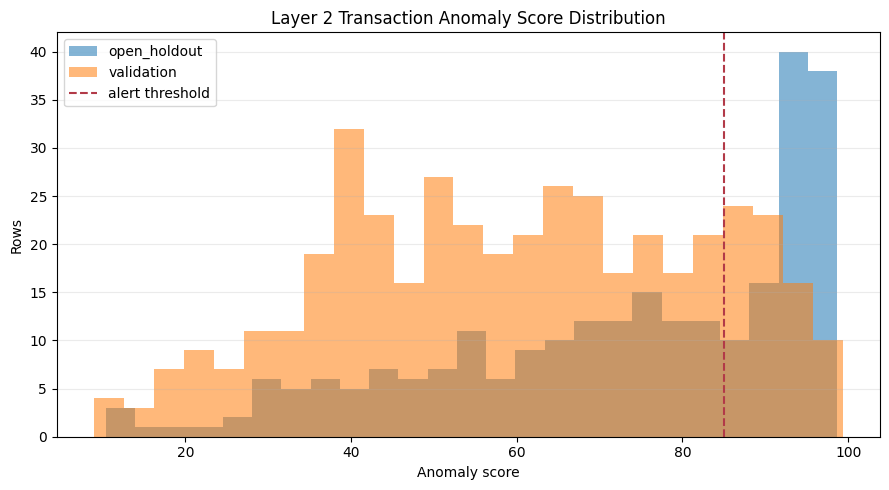

In [29]:
fig, ax = plt.subplots(figsize=(9, 5))
for split, group in anomalies.groupby('stage_b_split'):
    ax.hist(group['layer2_anomaly_score'], bins=25, alpha=0.55, label=split)
ax.axvline(85, color='#b23a48', linestyle='--', linewidth=1.5, label='alert threshold')
ax.set_title('Layer 2 Transaction Anomaly Score Distribution')
ax.set_xlabel('Anomaly score')
ax.set_ylabel('Rows')
ax.legend()
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()

In [30]:
country_goods_alerts = (
    anomalies[anomalies['layer2_anomaly_alert']]
    .groupby(['buy_buyer_country', 'goods_category'], dropna=False)
    .agg(alerts=('transaction_id', 'size'), avg_anomaly_score=('layer2_anomaly_score', 'mean'), avg_stage_c_probability=('stage_c_default_probability', 'mean'))
    .reset_index()
    .sort_values(['alerts', 'avg_anomaly_score'], ascending=False)
)
country_goods_alerts.head(20)

,buy_buyer_country,goods_category,alerts,avg_anomaly_score,avg_stage_c_probability
0,Algeria,Agricultural,5,82.3360,0.5031
94,Turkey,Pharmaceuticals,4,94.0481,0.8888
92,Turkey,Machinery,4,93.0893,0.8641
113,United States,Textiles,4,90.8424,0.8015
38,Iraq,Metals,4,90.5016,0.7032
72,Russia,Machinery,4,88.3957,0.4377
80,Saudi Arabia,Metals,4,85.6627,0.8892
21,Germany,Chemicals,4,84.1093,0.6681
3,Algeria,Machinery,4,84.0461,0.5602
17,France,Food,4,81.8799,0.4217


## Interpretation Notes

The Layer 2 results align with the project objective if they are presented as a monitoring and reviewer-prioritization layer, not as a second approval model. The strongest evidence is the portfolio drift: validation exposure is materially higher than training exposure on outstanding-to-revenue and total-exposure-to-revenue features. The cluster alerts are useful early warnings because several recent windows have low row counts; they should trigger review and data gathering rather than automatic rejection. The transaction anomaly table is appropriate for a per-deal review queue, especially because it includes open-holdout deals that do not yet have default labels.


## 6. Monitoring Cadence

| Cadence | Check | Human-review trigger |
|---|---|---|
| Weekly portfolio monitoring | Re-run cluster trends and PSI drift on the newest resolved batch | Any cluster alert, or any PSI feature above `0.25` |
| Per-deal intake | Score each new Stage-A-passed deal with Stage C and Layer 2 anomaly ranking | Stage C predicted default, anomaly score `>= 85`, or probability percentile `>= 95` |
| Credit committee review | Generate the LLM deal summary for deals in the high-risk review queue | Any Refer/Reject LLM verdict, unusual flag, or conflict between model output and business context |

## 7. Task 2B - Select One Deal for LLM Summary

By default this selects the highest-scoring anomaly. Change `DEAL_ID` to inspect any transaction in `layer2_scored_monitoring_frame.csv`.

In [35]:
# Default to the highest-risk alert because Task 2B asks for a useful human-review summary.
# Change DEAL_ID manually if you want to inspect a specific transaction.
high_risk_deals = anomalies[anomalies['layer2_anomaly_alert']].copy()
if high_risk_deals.empty:
    high_risk_deals = anomalies.copy()

DEAL_ID = high_risk_deals.sort_values('layer2_anomaly_score', ascending=False).iloc[0]['transaction_id']
# DEAL_ID = 'TX-001804'
DEAL_ID


'TX-004515'

In [36]:
deal_context = build_deal_context(
    transaction_id=DEAL_ID,
    monitoring_frame=monitoring,
    anomalies=anomalies,
    clusters=clusters,
    drift_report=drift,
)

display(Markdown('### Deal Context Sent to the LLM'))
print(json.dumps(deal_context, indent=2)[:7000])

### Deal Context Sent to the LLM

{
  "transaction_id": "TX-004515",
  "deal_snapshot": {
    "invoice_date": "2025-11-25T00:00:00",
    "stage_b_split": "validation",
    "invoice_amount_usd": 801378,
    "funded_amount_usd": 657129.96,
    "invoice_currency": "USD",
    "payment_terms_days": 90,
    "advance_pct": 0.82,
    "insurance_covered": true,
    "goods_category": "Chemicals",
    "exporter_id": "EXP-0156",
    "buyer_id": "BUY-0145",
    "buy_buyer_country": "Spain",
    "buy_buyer_sector": "Technology and IT",
    "buy_creditsafe_rating": "A",
    "buy_buyer_country_risk_score": 2,
    "buy_buyer_payment_history_dso_avg": 78,
    "exp_industry": "Food Producers",
    "exp_segment": "LC",
    "exp_years_in_business": 7,
    "exp_iscore": 803,
    "exp_current_ratio": 1.666612781,
    "exp_quick_ratio": 1.217827199,
    "exp_debt_to_equity": 0.4950693702,
    "exp_operating_margin_pct": 12.20418458,
    "exp_historical_on_time_payment_rate": 0.927,
    "exp_historical_dispute_rate": 0.005,
    "exp_concentrat

## 8. Task 2B - Prompt Used

The next cell prints the exact messages sent to OpenRouter.

In [37]:
messages = build_deal_summary_messages(deal_context)
for message in messages:
    display(Markdown(f"### {message['role'].title()} Message"))
    print(message['content'])

### System Message

You are a senior credit risk analyst supporting Rawasi, an SMB invoice discounting platform. Use only the provided structured data. Do not invent facts. Write for a human credit officer, not a data scientist. Return strict JSON only.


### User Message

Create a structured credit summary for the deal below.

Required JSON schema:
{
  "risk_verdict": "Approve | Refer | Reject",
  "confidence": "Low | Medium | High",
  "one_sentence_verdict": "One concise sentence with the verdict and why.",
  "top_three_factors": [
    {"factor": "Plain-English factor", "evidence": "Specific value or signal", "credit_implication": "Why it matters"},
    {"factor": "Plain-English factor", "evidence": "Specific value or signal", "credit_implication": "Why it matters"},
    {"factor": "Plain-English factor", "evidence": "Specific value or signal", "credit_implication": "Why it matters"}
  ],
  "unusual_flags_not_fully_captured_by_model": [
    {"flag": "Unusual pattern", "why_it_needs_human_review": "Short explanation"}
  ],
  "recommended_reviewer_actions": ["Action 1", "Action 2", "Action 3"]
}

Decision guidance:
- Approve only when Layer 1 and Layer 2 signals are both low risk.
- Refer when the deal is not an automatic reject but needs human review.
-

## 9. Task 2B - Call OpenRouter

Set your API key before running this cell:

```bash
export OPENROUTER_API_KEY='your_key_here'
export OPENROUTER_MODEL='openai/gpt-4o-mini'  # optional
```

The default model can be changed with `OPENROUTER_MODEL`. The helper returns both the raw model text and parsed JSON.

In [38]:
if not os.getenv('OPENROUTER_API_KEY'):
    display(Markdown('**OpenRouter call skipped.** Set `OPENROUTER_API_KEY` and rerun this cell.'))
else:
    llm_result = call_openrouter_deal_summary(deal_context)
    display(Markdown(f"### OpenRouter Model: `{llm_result['model']}`"))
    display(pd.DataFrame([llm_result.get('usage', {})]))
    display(Markdown('### Parsed Structured Credit Summary'))
    display(pd.json_normalize(llm_result['parsed_summary']))
    display(Markdown('### Raw LLM Content'))
    print(llm_result['raw_content'])

### OpenRouter Model: `openai/gpt-4o-mini`

,prompt_tokens,completion_tokens,total_tokens,cost,is_byok,prompt_tokens_details,cost_details,completion_tokens_details
0,1715,301,2016,0.0004,False,"{'cached_tokens': 0, 'cache_write_tokens': 0, ...","{'upstream_inference_cost': 0.00043785, 'upstr...","{'reasoning_tokens': 0, 'image_tokens': 0, 'au..."


### Parsed Structured Credit Summary

,risk_verdict,confidence,one_sentence_verdict,top_three_factors,unusual_flags_not_fully_captured_by_model,recommended_reviewer_actions
0,Refer,Medium,Refer the deal due to significant shifts in ex...,"[{'factor': 'Predicted Default Probability', '...","[{'flag': 'Layer 2 Anomaly Alert', 'why_it_nee...",[Conduct a deeper analysis of the significant ...


### Raw LLM Content

```json
{
  "risk_verdict": "Refer",
  "confidence": "Medium",
  "one_sentence_verdict": "Refer the deal due to significant shifts in exposure metrics despite a low predicted default probability.",
  "top_three_factors": [
    {
      "factor": "Predicted Default Probability",
      "evidence": "0",
      "credit_implication": "A predicted default probability of 0 indicates low immediate risk."
    },
    {
      "factor": "Insurance Coverage",
      "evidence": "true",
      "credit_implication": "Insurance coverage mitigates potential losses in case of default."
    },
    {
      "factor": "Significant Distribution Shifts",
      "evidence": "Multiple PSI values above 0.3",
      "credit_implication": "Significant shifts in outstanding to revenue and total exposure metrics suggest increased risk that needs further review."
    }
  ],
  "unusual_flags_not_fully_captured_by_model": [
    {
      "flag": "Layer 2 Anomaly Alert",
      "why_it_needs_human_review": "The layer 2 anomaly s